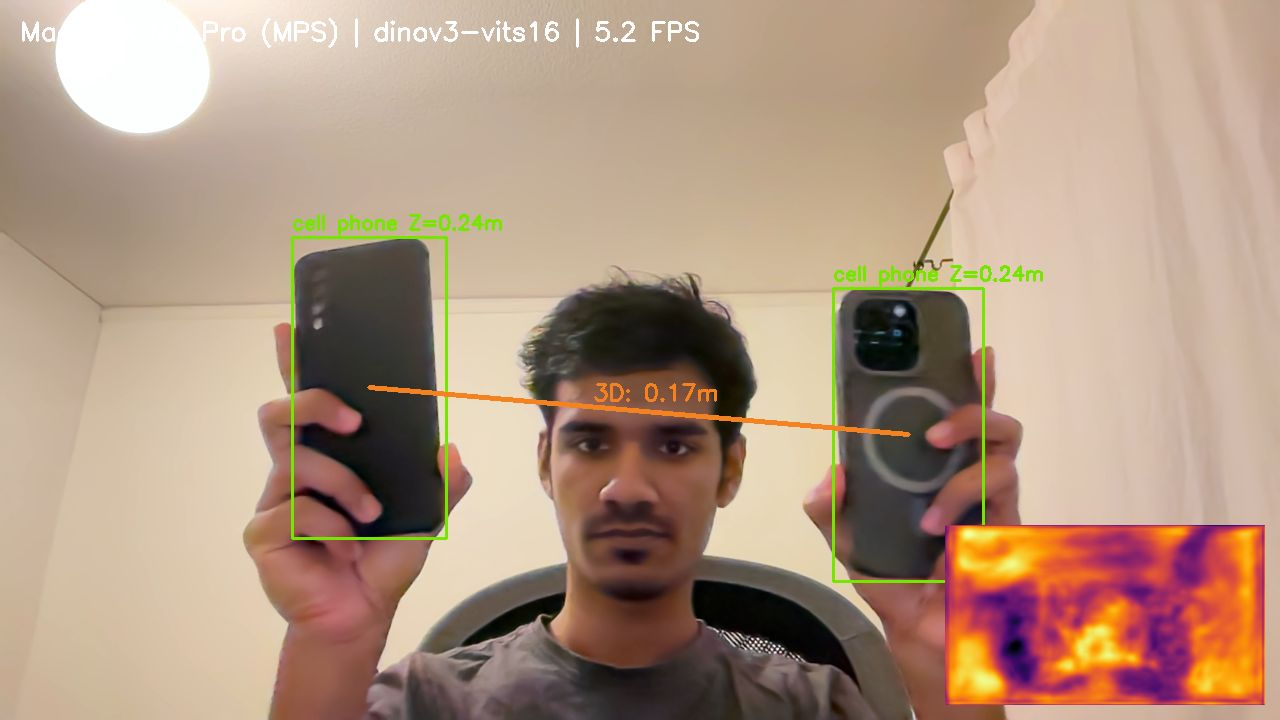

Stopped automatically after 15.0s (saved demo_thumb.jpg).


In [ ]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import time
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import timm
from IPython.display import display, clear_output, Image as IPyImage
from ultralytics import YOLO

# ==============================================================================
# 1. Self-Contained Model & 3D Geometry Functions (No external .py files needed)
# ==============================================================================
class DinoDepth(nn.Module):
    def __init__(self, variant="dinov3-vits16"):
        super().__init__()
        backbone_map = {
            "dinov3-vits16": ("vit_small_patch16_dinov3", 384),
            "dinov3-vitb16": ("vit_base_patch16_dinov3", 768),
            "dinov2-base":   ("vit_base_patch14_dinov2", 768),
        }
        timm_name, dim = backbone_map[variant]
        self.backbone = timm.create_model(timm_name, pretrained=True, num_classes=0, dynamic_img_size=True)
        for p in self.backbone.parameters():
            p.requires_grad = False

        # Lightweight Conv Decoder matching the trained head_*.pt weights
        self.head = nn.Sequential(
            nn.Conv2d(dim, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(32, 1, kernel_size=1),
            nn.Softplus(),
        )

    def forward(self, x):
        # ImageNet normalization
        mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
        x = (x - mean) / std
        feats = self.backbone.forward_features(x)
        # Drop prefix tokens (CLS + register tokens)
        n_prefix = getattr(self.backbone, "num_prefix_tokens", 1)
        patch_tokens = feats[:, n_prefix:, :]
        B, N, C = patch_tokens.shape
        h_p = x.shape[2] // 16
        w_p = x.shape[3] // 16
        feat_map = patch_tokens.transpose(1, 2).reshape(B, C, h_p, w_p)
        return self.head(feat_map).squeeze(1)

def intrinsics_safe(W, H, f_px, calib_w=4284, calib_h=5712):
    # Scale focal length proportionally to sensor width/height
    scale_x = W / float(calib_w)
    scale_y = H / float(calib_h)
    fx = f_px * scale_x
    fy = f_px * scale_y
    return fx, fy, W / 2.0, H / 2.0

def backproject(u, v, z, K):
    fx, fy, cx, cy = K
    X = (u - cx) * z / fx
    Y = (v - cy) * z / fy
    return np.array([X, Y, z], dtype=np.float32)

def box_depth(dmap, box, q=35):
    H, W = dmap.shape
    x1, y1, x2, y2 = map(int, box)
    # Sample inner 50% core of the bounding box to avoid background bleed
    dx, dy = int((x2 - x1) * 0.25), int((y2 - y1) * 0.25)
    cx1, cy1 = max(0, x1 + dx), max(0, y1 + dy)
    cx2, cy2 = min(W, max(cx1 + 1, x2 - dx)), min(H, max(cy1 + 1, y2 - dy))
    patch = dmap[cy1:cy2, cx1:cx2]
    return float(np.percentile(patch, q))

# ==============================================================================
# 2. Setup Apple Silicon MPS & Load Weights
# ==============================================================================
device = "mps" if torch.backends.mps.is_available() else "cpu"
MODEL_KEY = "dinov3-vits16"   # or "dinov3-vitb16"
SCALE_FACTOR = 0.3729        # 0.3729 for vits16, 0.3695 for vitb16

yolo = YOLO("yolo11s.pt")
depth_model = DinoDepth(MODEL_KEY).to(device)
depth_model.load_state_dict(torch.load(f"head_{MODEL_KEY}.pt", map_location=device, weights_only=True), strict=False)
depth_model.eval()

# ==============================================================================
# 3. Camera Auto-Detection (iPhone Continuity Camera -> MacBook Webcam Fallback)
# ==============================================================================
cap = cv2.VideoCapture(1, cv2.CAP_AVFOUNDATION)
time.sleep(0.8)  # Give iPhone Continuity Camera ~0.8s to wake up and chime

if cap.isOpened():
    F_PX = 3150.0  # iPhone Continuity Camera FOV
    print("Connected to iPhone Continuity Camera (index 1)")
else:
    cap.release()
    cap = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)
    F_PX = 2600.0  # MacBook built-in webcam FOV
    print("iPhone not detected — using MacBook Webcam (index 0)")

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

# ==============================================================================
# 4. Live Webcam Loop in VS Code Cell (Auto-Stops after MAX_SECONDS)
# ==============================================================================
MAX_SECONDS = 15.0  # Seconds to run before auto-stopping (for demo purposes)
start_t = time.time()

ema_dist = None
prev_t = time.time()
last_frame = None

try:
    while True:
        if time.time() - start_t >= MAX_SECONDS:
            if last_frame is not None:
                cv2.imwrite("demo_thumb.jpg", last_frame)
            print(f"Stopped automatically after {MAX_SECONDS}s (saved demo_thumb.jpg).")
            break

        ok, frame_bgr = cap.read()
        if not ok:
            print("Could not read from camera (check macOS camera permissions for VS Code).")
            break

        H, W = frame_bgr.shape[:2]
        K = intrinsics_safe(W, H, F_PX, 4284, 5712)

        # 2D Detection
        det = yolo.predict(frame_bgr, conf=0.35, verbose=False)[0]
        objs = [
            (box, det.names[cls_id])
            for box, cls_id in zip(det.boxes.xyxy.cpu().numpy(), det.boxes.cls.cpu().numpy().astype(int))
            if det.names[cls_id] not in {"person", "dining table", "chair", "couch", "bed"}
        ]
        objs = sorted(objs[:4], key=lambda x: (x[0][0] + x[0][2]) / 2.0)

        # Monocular Depth (384x512 is divisible by 16 for ViT-S/16)
        rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        inp = torch.from_numpy(rgb).permute(2, 0, 1).float().div(255.0).unsqueeze(0).to(device)
        inp = F.interpolate(inp, size=(384, 512), mode="bilinear", align_corners=False)
        with torch.no_grad():
            pred = depth_model(inp)
            dmap = F.interpolate(pred.unsqueeze(1), size=(H, W), mode="bilinear", align_corners=False)
            dmap = dmap.squeeze().cpu().numpy() * SCALE_FACTOR

        # 3D Backprojection & Overlay
        pts_3d, centers = [], []
        for box, lbl in objs:
            x1, y1, x2, y2 = map(int, box)
            u, v = (x1 + x2) // 2, (y1 + y2) // 2
            z = box_depth(dmap, box, q=35)
            pts_3d.append(backproject(u, v, z, K))
            centers.append((u, v))
            cv2.rectangle(frame_bgr, (x1, y1), (x2, y2), (0, 230, 118), 2)
            cv2.putText(frame_bgr, f"{lbl} Z={z:.2f}m", (x1, max(25, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 230, 118), 2)

        for i in range(len(pts_3d) - 1):
            d3d = float(np.linalg.norm(pts_3d[i] - pts_3d[i + 1]))
            ema_dist = d3d if ema_dist is None else 0.75 * ema_dist + 0.25 * d3d
            c1, c2 = centers[i], centers[i + 1]
            cv2.line(frame_bgr, c1, c2, (32, 130, 245), 3)
            mx, my = (c1[0] + c2[0]) // 2, (c1[1] + c2[1]) // 2
            cv2.putText(frame_bgr, f"3D: {d3d:.2f}m", (mx - 45, my - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.75, (32, 130, 245), 2)

        # Depth Map PiP (Bottom-Right)
        d_norm = cv2.normalize(dmap, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        d_color = cv2.applyColorMap(d_norm, cv2.COLORMAP_INFERNO)
        pip_w, pip_h = W // 4, H // 4
        frame_bgr[H - pip_h - 15 : H - 15, W - pip_w - 15 : W - 15] = cv2.resize(d_color, (pip_w, pip_h))

        # FPS Overlay & Render Directly in VS Code Cell
        now = time.time()
        fps = 1.0 / max(1e-5, now - prev_t)
        prev_t = now
        cv2.putText(frame_bgr, f"MacBook M2 Pro (MPS) | {MODEL_KEY} | {fps:.1f} FPS", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.85, (255, 255, 255), 2)

        last_frame = frame_bgr.copy()
        _, jpg = cv2.imencode(".jpg", frame_bgr, [int(cv2.IMWRITE_JPEG_QUALITY), 80])
        clear_output(wait=True)
        display(IPyImage(data=jpg.tobytes(), width=900))

except KeyboardInterrupt:
    print("Live demo stopped manually.")
finally:
    cap.release()